# EDA: предсказание оценки товара по тексту отзыва (Wildberries)

**Задача.** По тексту отзыва покупателя предсказать оценку товара 1–5. Это многоклассовая (или ординальная) классификация текстов на русском языке.

**Данные** собраны нашим парсером (`parser/wb_parser.py`) с Wildberries:
- `data/wb_reviews.csv.gz`: 300k отзывов. Таргет `rating`, текст `text` / `pros` / `cons`, метаданные отзыва и товара.
- `data/wb_products.csv`: 9k товаров (описание, категория, средний рейтинг).

Товары выбирались случайно по `nm_id`, поэтому выборка не смещена к популярной выдаче. С одного товара взято не больше 100 отзывов.

**План**
1. Общие статистики
2. Пропуски
3. Ошибочные значения и шум в разметке
4. Выбросы
5. Целевая переменная
6. Признаки и их связь с таргетом
7. Корреляции и pairplot
8. Текст: словарь и n-граммы
9. Аугментации
10. Бейзлайн
11. Выводы

In [1]:
import ast
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             mean_absolute_error)
from sklearn.model_selection import GroupShuffleSplit

sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 150)
RATING_PALETTE = sns.color_palette('RdYlGn', 5)
SEED = 0

In [2]:
reviews = pd.read_csv('data/wb_reviews.csv.gz')
products = pd.read_csv('data/wb_products.csv')
print(f'reviews: {reviews.shape}, products: {products.shape}')
reviews.head(3)

reviews: (300118, 19), products: (9172, 11)


,review_id,imt_id,nm_id,rating,text,pros,cons,created_date,color,size,votes_plus,votes_minus,has_answer,excluded_from_rating,subject,subject_root,full_text,product_name,brand
0,qkmKAPONcI1AykyT3buv,107707748,163212882,5,NaN,На телефон подошёл идеально,NaN,2026-02-15T01:10:15Z,Черный · силикон,0,0,0,True,"{'isExcluded': False, 'reasons': []}",Чехлы для телефонов,Аксессуары для электроники,Достоинства: На телефон подошёл идеально,Силиконовый чехол с рисунком для Honor 50 / Nova 9,COVERGOOD
1,VyzRsIqtBjc64zExgROa,107707748,120053357,5,NaN,"Понравилось, пользуюсь давно",NaN,2025-09-24T06:09:10Z,"Черный, зеленый неон · силикон",0,0,0,True,"{'isExcluded': False, 'reasons': []}",Чехлы для телефонов,Аксессуары для электроники,"Достоинства: Понравилось, пользуюсь давно",Силиконовый чехол с рисунком для Honor 50 / Nova 9,COVERGOOD
2,iXq2HzHOSmQ1bxGT4aEF,107707748,120053343,2,NaN,NaN,"Сам чехол красивый, сел на тел хорошо, плотно. Но буквально через месяц пожелтели....",2025-06-14T03:43:12Z,фиолетовый,0,0,0,True,"{'isExcluded': False, 'reasons': []}",Чехлы для телефонов,Аксессуары для электроники,"Недостатки: Сам чехол красивый, сел на тел хорошо, плотно. Но буквально через месяц пожелтели....",Силиконовый чехол с рисунком для Honor 50 / Nova 9,COVERGOOD


## 1. Общие статистики

In [3]:
reviews.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
review_id,300118,300118,qkmKAPONcI1AykyT3buv,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
imt_id,300118.0,NaN,NaN,NaN,399506068.998917,673640404.907413,1977715.0,122849378.0,199266680.0,390840031.0,4243556465.0
nm_id,300118.0,NaN,NaN,NaN,238410723.982334,184519081.92356,1633052.0,120926755.0,195877738.0,297727416.0,1721702801.0
rating,300118.0,NaN,NaN,NaN,4.424143,1.184967,1.0,5.0,5.0,5.0,5.0
text,195891,182125,Рекомендую,670,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pros,114871,99349,Качество,633,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cons,46354,35319,Нет,2862,NaN,NaN,NaN,NaN,NaN,NaN,NaN
created_date,300118,299628,2023-06-20T17:12:23Z,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
color,247542,11712,черный,30322,NaN,NaN,NaN,NaN,NaN,NaN,NaN
size,266132,1739,0,174568,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
products.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
imt_id,9172.0,NaN,NaN,NaN,417271861.981138,684464227.999438,1977715.0,128517419.75,209502869.0,429478203.0,4243556465.0
nm_id,9172.0,NaN,NaN,NaN,262499559.191343,201227199.710546,10003406.0,131064464.75,211478633.5,345783680.25,899743861.0
name,9127,8804,Платье,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subject,9172,1930,Чехлы для телефонов,467,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subject_root,9172,93,Одежда,1254,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,8440,7018,Xiaomi,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,8983,8954,Защитный эстетичный чехол для телефона из прозрачного силикона с противоударными углами. Принты у2к aesthetic angelcore opium cutecore dreamcore т...,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
options,9111,9060,Страна производства: Китай,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_rating,9172.0,NaN,NaN,NaN,4.678184,0.36658,1.0,4.6,4.8,4.9,5.0
feedback_count,9172.0,NaN,NaN,NaN,512.327846,3062.716931,3.0,16.0,48.0,184.0,145434.0


Признаки отзыва:

| признак | тип | описание |
|---|---|---|
| `rating` | target, 1–5 | оценка покупателя |
| `text`, `pros`, `cons` | текст | основной текст, «Достоинства», «Недостатки» |
| `full_text` | текст | склейка трёх полей (собрана в `parser/export.py`) |
| `created_date` | дата | дата отзыва |
| `color`, `size` | категориальный | выбранный вариант товара |
| `votes_plus`, `votes_minus` | счётчик | лайки и дизлайки отзыва |
| `has_answer` | bool | ответил ли продавец |
| `excluded_from_rating` | dict | исключил ли WB отзыв из рейтинга товара и почему |
| `subject`, `subject_root` | категориальный | категория товара (1 930 конечных / 93 корневых) |
| `brand`, `product_name`, `imt_id` | категориальный | товар |

## 2. Пропуски

In [5]:
na = pd.DataFrame({'n_missing': reviews.isna().sum(), 'share': reviews.isna().mean().round(4)})
na[na.n_missing > 0].sort_values('share', ascending=False)

,n_missing,share
cons,253764,0.8455
pros,185247,0.6172
text,104227,0.3473
color,52576,0.1752
size,33986,0.1132
brand,21402,0.0713
product_name,833,0.0028


In [6]:
# доля пропусков в отзыве: насколько «разрежен» датасет
print(f'ячеек пропущено: {reviews.isna().mean().mean():.1%}')
print(f'строк хотя бы с одним пропуском: {reviews.isna().any(axis=1).mean():.1%}')

# какие текстовые поля заполняются вместе
fields = reviews[['text', 'pros', 'cons']].notna()
fields.value_counts().rename('n').to_frame().assign(share=lambda d: (d.n / d.n.sum()).round(3))

ячеек пропущено: 11.4%
строк хотя бы с одним пропуском: 96.9%


n  share
text  pros  cons                
True  False False  166775  0.556
False True  False   75938  0.253
      False True    15916  0.053
True  True  True    15509  0.052
False True  True    12373  0.041
True  True  False   11051  0.037
      False True     2556  0.009

**Гипотезы о пропусках.**
- `text` / `pros` / `cons`: это не пропуски, а незаполненные поля формы. Каждое поле опционально, парсер оставлял только отзывы, где заполнено хотя бы одно. Заполним пустой строкой. Сам факт заполнения может быть признаком: проверим в п. 6.
- `color` / `size`: у товара нет вариантов цвета или размера. Проверим, что пропуски сосредоточены в категориях, где вариантов быть не может (электроника, лекарства).
- `brand`: товар без бренда (no-name). Проверим, отличается ли у таких товаров рейтинг.
- `product_name`: несколько карточек без названия, на задачу не влияет.

In [7]:
# пропуск color/size по корневым категориям
miss_by_cat = (reviews.groupby('subject_root')[['color', 'size']]
               .agg(lambda s: s.isna().mean()).join(reviews.subject_root.value_counts()))
miss_by_cat[miss_by_cat['count'] > 1000].sort_values('color', ascending=False).round(3).head(12)

,color,size,count
subject_root,,,
Автозапчасти,0.734,0.120,2167
Книжная продукция и диски,0.584,0.158,4191
Продукты,0.503,0.142,8268
Бытовая химия,0.447,0.157,2510
Здоровье,0.412,0.149,4825
Красота,0.396,0.195,21197
Все для садоводства,0.319,0.124,10198
Товары для животных,0.301,0.159,4927
Техника для кухни,0.282,0.172,1456


In [8]:
print(reviews['size'].value_counts().head(8))

size
0     174568
M       4651
L       4478
S       3619
XL      3006
38      2645
44      2404
40      2300
Name: count, dtype: int64


Гипотеза подтверждается: `color` чаще всего пропущен там, где у товара обычно нет цветовых вариантов: автозапчасти (73%), книги (58%), продукты (50%). В одежде и обуви он почти всегда заполнен.

У `size` есть **скрытый пропуск**: значение `'0'` (58% отзывов) означает «без размера». Его тоже переводим в пропуск.

Строк хотя бы с одним пропуском 97%, но это из-за опциональных полей формы: «разреженность» здесь структурная, а не следствие плохого сбора.

In [9]:
reviews['size'] = reviews['size'].replace('0', np.nan)
for col in ['color', 'size', 'brand']:
    print(f'{col:>6} missing: {reviews[col].isna().mean():.1%}  '
          f'mean rating missing / present: '
          f'{reviews.loc[reviews[col].isna(), "rating"].mean():.3f} / '
          f'{reviews.loc[reviews[col].notna(), "rating"].mean():.3f}')

 color missing: 17.5%  mean rating missing / present: 4.359 / 4.438
  size missing: 69.5%  mean rating missing / present: 4.412 / 4.453
 brand missing: 7.1%  mean rating missing / present: 4.268 / 4.436


У товаров **без бренда** средняя оценка заметно ниже (4.27 против 4.44), значит пропуск информативен.

**Обработка:** тексты → `''`, `color` / `size` / `brand` → флаги `*_missing` плюс категория `'нет'`. Удалять строки не нужно: пропуски осмысленные.

In [10]:
for col in ['text', 'pros', 'cons', 'product_name']:
    reviews[col] = reviews[col].fillna('')
for col in ['color', 'size', 'brand']:
    reviews[f'{col}_missing'] = reviews[col].isna().astype(int)
    reviews[col] = reviews[col].fillna('нет')

## 3. Ошибочные значения и шум в разметке

In [11]:
# таргет: только 1..5, id отзывов уникальны, даты в разумных пределах
reviews['created_date'] = pd.to_datetime(reviews.created_date, format='ISO8601', utc=True)
print('ratings:', sorted(reviews.rating.unique()))
print('duplicate review_id:', reviews.review_id.duplicated().sum())
print('dates:', reviews.created_date.min().date(), '..', reviews.created_date.max().date())
print('negative votes:', (reviews[['votes_plus', 'votes_minus']] < 0).sum().sum())

ratings: [1, 2, 3, 4, 5]
duplicate review_id: 0
dates: 2014-10-22 .. 2026-10-07
negative votes: 0


Формально ошибочных значений нет. Но в данных есть разметка самого Wildberries: поле `excluded_from_rating`, то есть исключён ли отзыв из рейтинга товара и по какой причине.

In [12]:
excl = reviews.excluded_from_rating.apply(ast.literal_eval)
reviews['excl_reasons'] = excl.apply(lambda d: ','.join(d['reasons']) or 'ok')
reviews.groupby('excl_reasons').rating.agg(['size', 'mean']).round(2).sort_values('size', ascending=False)

,size,mean
excl_reasons,,
ok,294331,4.45
hasIncludedChild,2705,3.77
notProduct,2686,2.47
sentimentCollision,379,2.02
"notProduct,sentimentCollision",17,2.88


In [13]:
# примеры по каждой причине исключения
for reason in ['sentimentCollision', 'notProduct', 'hasIncludedChild']:
    print(f'=== {reason}')
    sample = reviews[reviews.excl_reasons == reason].sample(4, random_state=SEED)
    for _, row in sample.iterrows():
        print(f'  {row.rating}★ | {row.full_text[:130]!r}')

=== sentimentCollision
  5★ | 'Недостатки: Не соответствует описанию в карточке товара.'
  1★ | 'Достоинства: Качество и красота'
  1★ | 'Всё хорошо\nДостоинства: Пришло по розмеру'
  5★ | 'Недостатки: Очень мелкие и сухие'
=== notProduct
  2★ | 'Недостатки: Пришли поломанные'
  2★ | 'Не мой цвет.'
  4★ | 'Недостатки: Цвет не тот'
  1★ | 'Достоинства: Отношение к монетам хамское, прислали насыпью, все побитые, ни какого уважения к покупателю'
=== hasIncludedChild
  5★ | 'Достоинства: Удобный дозатор'
  5★ | 'Достоинства: Очень красивые'
  1★ | 'На втором сезоне появились большие грыжи!\nДостоинства: Можно заказать по одному колесу\nНедостатки: Резина слишком мягкая на втором'
  5★ | 'Достоинства: Эластан конечно чувствуется, приемлемая цена.'


- **`sentimentCollision`** (379 отзывов): WB сам определил, что тон текста противоречит оценке («Не соответствует описанию» стоит с 5★, «Качество и красота» с 1★). Это **шум в разметке**: удаляем из обучения.
- **`notProduct`** (~2.7k): по мнению WB, отзыв не о свойствах товара, а о доставке, повреждениях в пути или ошибке сборки заказа («Пришли поломанные», «Цвет не тот»). Средняя оценка 2.5. Метка честная, но текст говорит о логистике. Оставляем, но помечаем флагом `not_product`.
- **`hasIncludedChild`** (~2.7k): у отзыва есть более новая версия от того же покупателя (дополненный отзыв). Это почти дубликаты: оставляем, но при split по товарам они не утекут.

In [14]:
reviews = reviews[~reviews.excl_reasons.str.contains('sentimentCollision')].reset_index(drop=True)
reviews['not_product'] = reviews.excl_reasons.str.contains('notProduct').astype(int)
print(f'after drop: {len(reviews):,}')

after drop: 299,722


### Некачественные тексты

In [15]:
text = reviews.full_text
cyr_share = text.str.count('[А-Яа-яЁё]') / text.str.len()
quality = pd.Series({
    'без кириллицы (эмодзи, латиница, символы)': (cyr_share == 0).sum(),
    'кириллицы < 50%': (cyr_share < 0.5).sum(),
    'короче 3 слов': (text.str.split().str.len() < 3).sum(),
    'точные дубликаты текста': text.duplicated().sum(),
})
print(quality.to_string())
print('\nпримеры без кириллицы:', text[cyr_share == 0].sample(8, random_state=SEED).tolist())

без кириллицы (эмодзи, латиница, символы)      175
кириллицы < 50%                                494
короче 3 слов                                22508
точные дубликаты текста                      16785

примеры без кириллицы: ['👍👍👍👍👍👍👍👍👍👍', '👍👍👍👍👍👍👍👍👍👍👍', '50%50 ........', '👍👍👍👍👍👍👍👍👍👍👍', '👍👍👍👍👍👍👍👍👍👍👍', '👍👍👍👍♥️♥️♥️♥️', '\U0001faf6🏻\U0001faf6🏻\U0001faf6🏻❤️👍🏻', '👍👍👍👍👍👍👍👍👍👍']


In [16]:
# самые частые тексты-шаблоны и их оценки
top_dups = text.value_counts().head(12).index
reviews[text.isin(top_dups)].groupby('full_text').rating.agg(['size', 'mean']).sort_values('size', ascending=False).round(2)

,size,mean
full_text,,
Все отлично,293,4.97
Рекомендую,249,4.97
Все хорошо,239,4.97
Всё отлично,220,4.96
Достоинства: Все отлично,201,4.98
Соответствует описанию,169,4.98
Достоинства: Всё отлично,158,4.99
Всё хорошо,150,4.95
Хорошее качество,129,5.00


- ~5.6% текстов это точные дубликаты, в основном шаблоны вроде «Все отлично» или «Рекомендую» со средней оценкой ~4.9. Это не ошибка, а реальное поведение пользователей, поэтому оставляем. Но при split важно, чтобы модель не «запоминала» их, а метрики на них будут завышены.
- Отзывы без кириллицы почти все из эмодзи (👍👍👍, ❤️). Для TF-IDF они пустые, для трансформеров информативны. Оставляем: их мало (<0.1%).

## 4. Выбросы

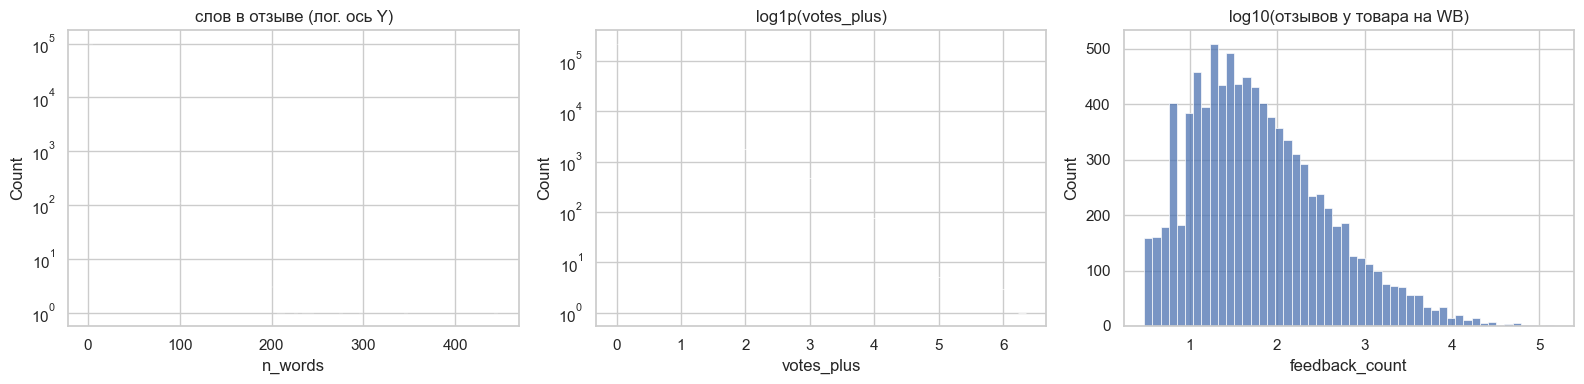

In [17]:
reviews['n_chars'] = reviews.full_text.str.len()
reviews['n_words'] = reviews.full_text.str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(reviews.n_words, bins=100, log_scale=(False, True), ax=axes[0])
axes[0].set_title('слов в отзыве (лог. ось Y)')
sns.histplot(np.log1p(reviews.votes_plus), bins=50, log_scale=(False, True), ax=axes[1])
axes[1].set_title('log1p(votes_plus)')
sns.histplot(np.log10(products.feedback_count), bins=50, ax=axes[2])
axes[2].set_title('log10(отзывов у товара на WB)')
plt.tight_layout()
plt.show()

In [18]:
for col in ['n_words', 'votes_plus', 'votes_minus']:
    q1, q3 = reviews[col].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    print(f'{col:>11}: IQR upper={upper:.0f}, outliers={(reviews[col] > upper).mean():.1%}, '
          f'p99={reviews[col].quantile(0.99):.0f}, max={reviews[col].max()}')

    n_words: IQR upper=32, outliers=6.6%, p99=64, max=447
 votes_plus: IQR upper=2, outliers=7.9%, p99=14, max=573
votes_minus: IQR upper=0, outliers=13.0%, p99=4, max=210


In [19]:
# самые длинные отзывы: полноценные тексты, не мусор
for t in reviews.nlargest(3, 'n_words').full_text:
    print(t[:300].replace('\n', ' / '), '...\n')

"Мне нужна была всего одна причина, чтобы остаться" /  / Скажу честно, я в слезах. И теперь я могу с полной уверенностью заявить, что книги от соавторства К.О.В.Ш для меня становятся автоматически покупаемыми+читаемыми, потому что это просто прекрасно! В октябре уже прошедшего года я была под впечатлени ...

Молды пришли вовремя, но в отвратительном качестве , забирала не сома человек не разбирается просто принес мне . Не обратила внимание закинув на полку сегодня достаю на пробу маленький с дыркой на верху . Мало того что брак так он ещё и не сходился склеила термоклеем залила больше половины молда нач ...

Не хотел писать отзыв сразу, думал, подожду решения Wildberries по отказу продавца на возврат некомплектного товара. Но потом понял, что решение площадки вряд ли изменит мое мнение о продавце, который, вероятно, взял за правило известную фразу от Чехова – «этого не может быть, потому что этого не мо ...



- Распределения длины текста и голосов имеют **тяжёлый правый хвост**. По IQR «выбросами» оказываются 6.6% отзывов по длине, но это реальные развёрнутые отзывы, а не ошибки. Удалять их не будем. Для моделей: `log1p` для счётчиков, обрезка текста до ~128 токенов (покрывает >99% отзывов).
- `votes_*`: у большинства отзывов 0 голосов, поэтому IQR формально объявляет выбросом любой голос (13% у `votes_minus`). 99% отзывов имеют ≤14 лайков, максимум 573. Логарифмируем.
- Число отзывов у товара на WB от 3 до 145k (log-нормальное). Именно поэтому парсер ограничивал выборку 100 отзывами на товар.

## 5. Целевая переменная

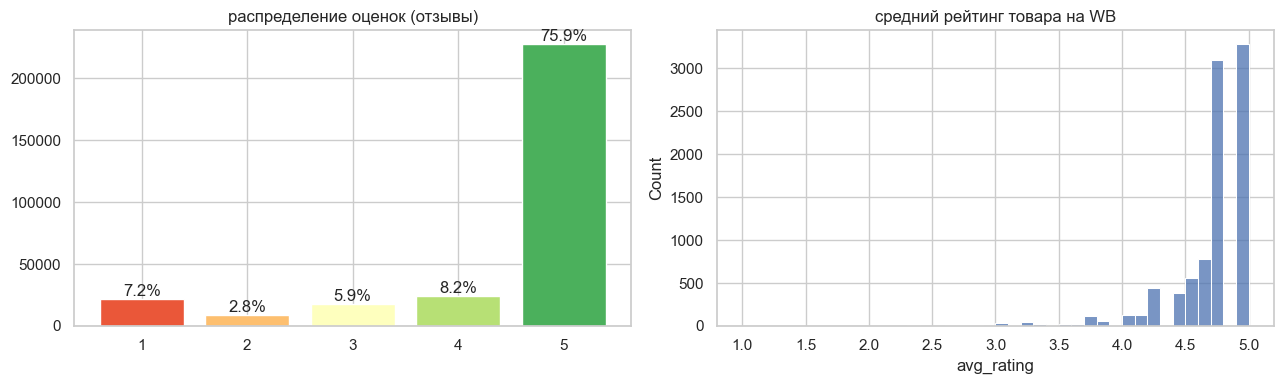

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts = reviews.rating.value_counts().sort_index()
axes[0].bar(counts.index, counts.values, color=RATING_PALETTE)
for x, y in zip(counts.index, counts.values):
    axes[0].text(x, y, f'{y / counts.sum():.1%}', ha='center', va='bottom')
axes[0].set_title('распределение оценок (отзывы)')
sns.histplot(products.avg_rating, bins=40, ax=axes[1])
axes[1].set_title('средний рейтинг товара на WB')
plt.tight_layout()
plt.show()

- **Сильный дисбаланс:** 5★ составляют 76%, 2★ всего 2.8%. Константный ответ «5» даёт accuracy 0.76, поэтому accuracy как метрика не подходит. Будем использовать **macro-F1** (качество на редких классах) и **MAE** (оценки упорядочены, ошибка 1↔5 хуже, чем 4↔5).
- Распределение U-образное: 1★ встречается чаще, чем 2★ и 3★. Недовольные покупатели склонны ставить сразу минимум.
- Для борьбы с дисбалансом: `class_weight`, сбалансированная версия датасета (`data/wb_reviews_balanced.csv`, андерсэмплинг до 8.5k на класс) или переход к ординальной регрессии.
- Средний рейтинг товара сосредоточен в 4.5–4.9. Постановка «рейтинг товара по описанию» имеет очень узкий таргет, поэтому основной оставляем постановку по отзывам.

## 6. Признаки и их связь с таргетом

In [21]:
emoji_re = re.compile('[\U0001F300-\U0001FAFF\u2600-\u27BF]')
reviews['has_text'] = (reviews.text != '').astype(int)
reviews['has_pros'] = (reviews.pros != '').astype(int)
reviews['has_cons'] = (reviews.cons != '').astype(int)
reviews['n_exclam'] = reviews.full_text.str.count('!')
reviews['n_emoji'] = reviews.full_text.str.count(emoji_re)
reviews['caps_share'] = reviews.full_text.str.count('[А-ЯЁA-Z]') / reviews.n_chars
reviews['year'] = reviews.created_date.dt.year
reviews['log_votes_plus'] = np.log1p(reviews.votes_plus)
reviews['log_votes_minus'] = np.log1p(reviews.votes_minus)
reviews['has_answer'] = reviews.has_answer.astype(int)

# признаки уровня товара
prod = products[['imt_id', 'avg_rating', 'feedback_count']].assign(
    log_feedback_count=lambda d: np.log10(d.feedback_count))
reviews = reviews.merge(prod[['imt_id', 'avg_rating', 'log_feedback_count']], on='imt_id', how='left')

FEATURES = ['n_words', 'has_text', 'has_pros', 'has_cons', 'n_exclam', 'n_emoji', 'caps_share',
            'log_votes_plus', 'log_votes_minus', 'has_answer', 'brand_missing', 'color_missing',
            'size_missing', 'not_product', 'year', 'avg_rating', 'log_feedback_count']
reviews.groupby('rating')[FEATURES].mean().T.round(3)

rating,1,2,3,4,5
n_words,15.717,16.080,15.705,15.789,11.009
has_text,0.633,0.628,0.613,0.647,0.660
has_pros,0.194,0.206,0.246,0.320,0.424
has_cons,0.401,0.402,0.403,0.322,0.084
n_exclam,0.437,0.232,0.172,0.130,0.382
n_emoji,0.095,0.067,0.059,0.068,0.243
caps_share,0.039,0.036,0.036,0.035,0.043
log_votes_plus,0.377,0.329,0.282,0.274,0.299
log_votes_minus,0.243,0.208,0.175,0.142,0.103
has_answer,0.707,0.719,0.720,0.730,0.767


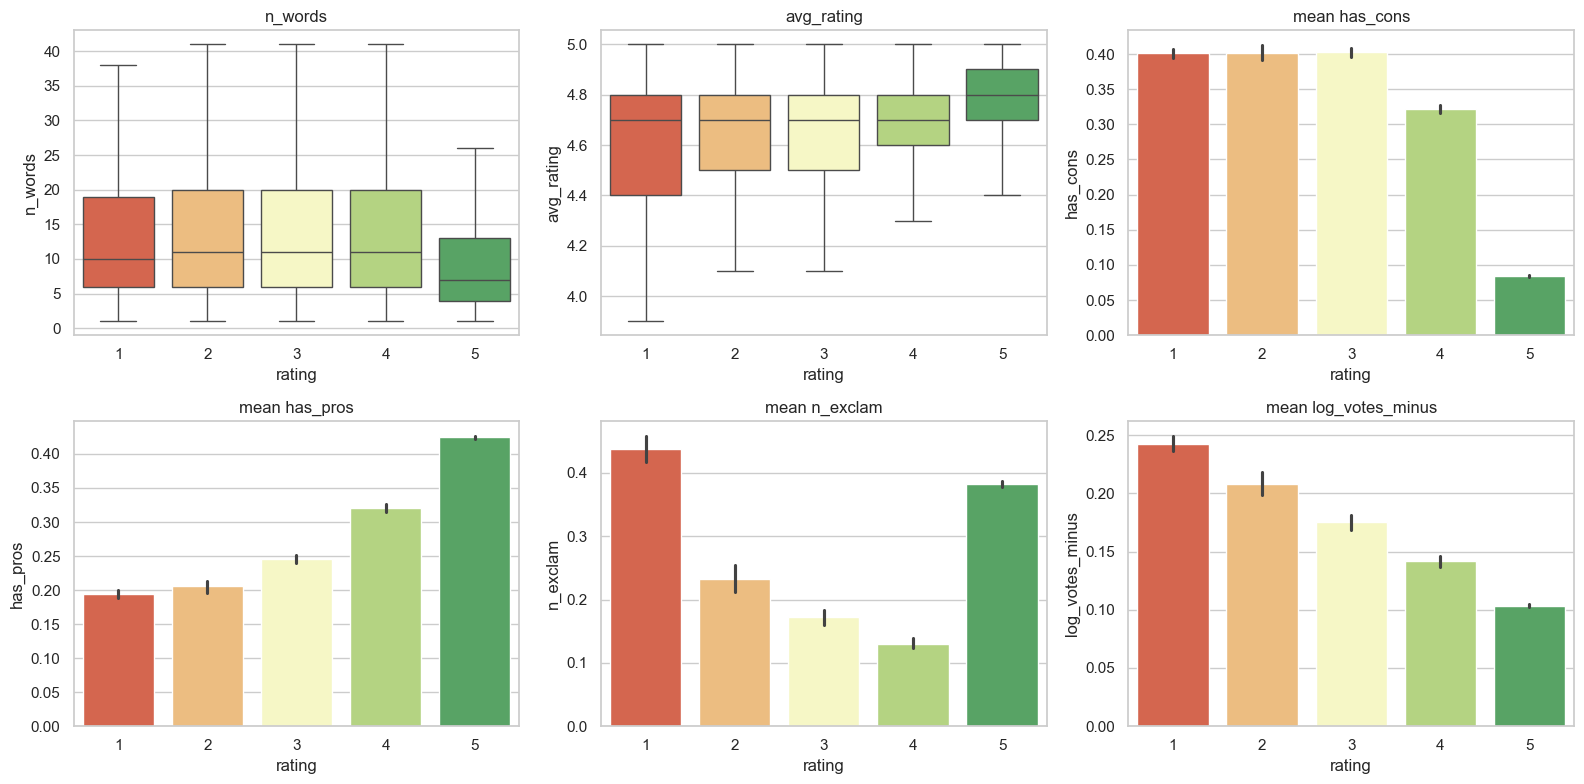

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat[:2], ['n_words', 'avg_rating']):
    sns.boxplot(data=reviews, x='rating', y=col, hue='rating', palette=RATING_PALETTE,
                legend=False, showfliers=False, ax=ax)
    ax.set_title(col)
for ax, col in zip(axes.flat[2:], ['has_cons', 'has_pros', 'n_exclam', 'log_votes_minus']):
    sns.barplot(data=reviews, x='rating', y=col, hue='rating', palette=RATING_PALETTE,
                legend=False, ax=ax)
    ax.set_title(f'mean {col}')
plt.tight_layout()
plt.show()

- **Длина:** у 5★ отзывы короче (медиана 7 слов против 10–11), а у 1–4★ длина почти одинакова. Довольные пишут «Всё отлично», недовольные объясняют.
- **`has_cons`:** «Недостатки» заполнены у ~40% отзывов с 1–3★ и только у 8% пятёрок. Это один из самых сильных неклассических признаков. **`has_pros`** наоборот растёт с оценкой.
- **`votes_minus`:** негативные отзывы чаще дизлайкают: среднее `log_votes_minus` падает от 0.24 у 1★ до 0.10 у 5★. Вероятно, это продавец или довольные покупатели.
- **`avg_rating` товара:** сильно связан с оценкой отзыва, но это **утечка таргета**: средний рейтинг считается в том числе по этому отзыву. В модель не берём, используем только для анализа.
- **`n_exclam`:** U-образная зависимость, восклицают при крайних оценках (1★ и 5★). **`n_emoji`:** эмодзи в основном у 5★ (0.24 на отзыв против 0.06–0.1 у остальных).

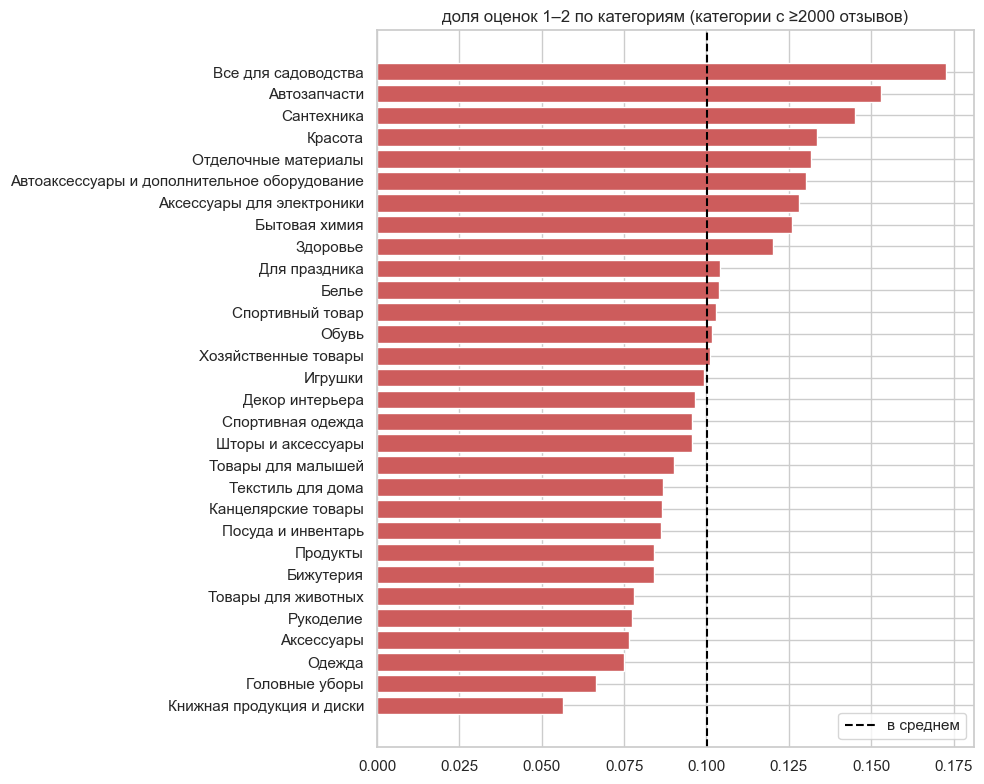

In [23]:
# категориальные признаки: категория товара
cat = (reviews.groupby('subject_root')
       .agg(n=('rating', 'size'), mean_rating=('rating', 'mean'), share_neg=('rating', lambda r: (r <= 2).mean()))
       .query('n >= 2000').sort_values('share_neg'))
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(cat.index, cat.share_neg, color='indianred')
ax.axvline((reviews.rating <= 2).mean(), color='black', ls='--', label='в среднем')
ax.set_title('доля оценок 1–2 по категориям (категории с ≥2000 отзывов)')
ax.legend()
plt.tight_layout()
plt.show()

In [24]:
# сводная таблица: категория × оценка, доли по строке
top_cats = reviews.subject_root.value_counts().head(10).index
pd.crosstab(reviews.subject_root, reviews.rating, normalize='index').loc[top_cats].round(3)

rating,1,2,3,4,5
subject_root,,,,,
Одежда,0.049,0.026,0.064,0.107,0.755
Красота,0.097,0.036,0.067,0.075,0.724
Обувь,0.071,0.031,0.071,0.114,0.714
Аксессуары,0.053,0.024,0.054,0.080,0.790
Текстиль для дома,0.056,0.030,0.064,0.083,0.766
Аксессуары для электроники,0.096,0.032,0.063,0.076,0.733
Рукоделие,0.054,0.024,0.054,0.079,0.789
Посуда и инвентарь,0.064,0.023,0.048,0.070,0.796
Все для садоводства,0.135,0.038,0.060,0.064,0.703


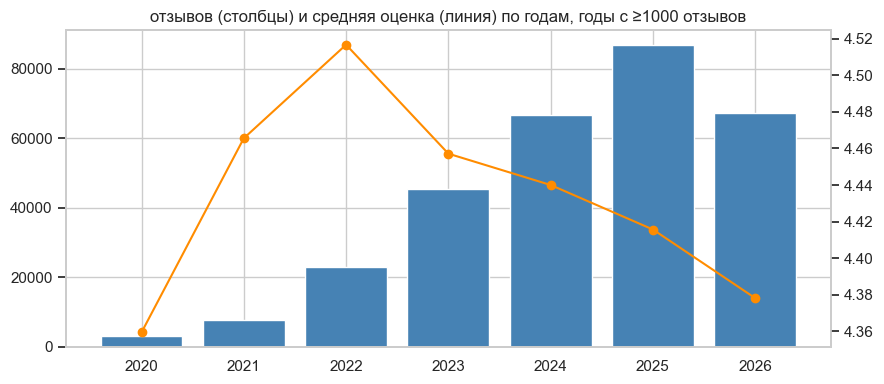

In [25]:
# время: число отзывов и средняя оценка по годам
by_year = reviews.groupby('year').rating.agg(['size', 'mean']).query('size >= 1000')
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(by_year.index, by_year['size'], color='steelblue')
ax2 = ax1.twinx()
ax2.plot(by_year.index, by_year['mean'], 'o-', color='darkorange')
ax2.grid(False)
ax1.set_title('отзывов (столбцы) и средняя оценка (линия) по годам, годы с ≥1000 отзывов')
plt.tight_layout()
plt.show()

In [26]:
# форма отзыва менялась со временем: доля заполненных полей по годам
reviews[reviews.year >= 2020].groupby('year')[['has_text', 'has_pros', 'has_cons']].mean().round(3)

,has_text,has_pros,has_cons
year,,,
2020,1.000,0.000,0.000
2021,1.000,0.000,0.000
2022,1.000,0.000,0.000
2023,1.000,0.000,0.000
2024,0.769,0.257,0.113
2025,0.376,0.702,0.283
2026,0.486,0.547,0.213


**До 2024 года полей «Достоинства» / «Недостатки» не существовало**: у всех отзывов 2020–2023 заполнен только `text`. С 2024 года WB поменял форму отзыва, и в 2025 году уже 70% отзывов содержат «Достоинства», а основной текст только 38%. Поэтому `has_pros` / `has_text` сильно коррелируют с годом (ρ ≈ ±0.5).

Следствия:
- признаки `has_pros` / `has_cons` информативны только для отзывов с 2024 года, для старых они всегда 0;
- для модели надёжнее склеенный `full_text`. Если брать признаки полей, то вместе с годом (или только на свежих данных);
- для продакшена это пример реального **дрейфа данных**: изменение интерфейса площадки меняет распределение входов.

In [27]:
# разнородность оценок внутри товара: доля дисперсии, объяснённая товаром
per_item = reviews.groupby('imt_id').rating.agg(['size', 'mean', 'std']).query('size >= 10')
between = reviews.groupby('imt_id').rating.transform('mean').var()
print(f'товаров с ≥10 отзывами: {len(per_item):,}, средний std оценки внутри товара: {per_item["std"].mean():.2f}')
print(f'доля дисперсии оценки, объяснённая товаром: {between / reviews.rating.var():.1%}')

товаров с ≥10 отзывами: 5,518, средний std оценки внутри товара: 1.05
доля дисперсии оценки, объяснённая товаром: 13.2%


- **Категория** влияет на оценку: доля негатива от ~7% (одежда, аксессуары) до ~17% (садоводство: всхожесть семян, живые растения). Категорию можно подавать в модель как признак.
- **Год:** с 2022 года средняя оценка медленно снижается (≈4.5 → 4.4), объём отзывов растёт вместе с WB. Сдвиг небольшой, но для продакшена стоит учитывать дрейф.
- **Товар** объясняет 13% дисперсии оценки (std внутри товара ≈ 1.05). Значит, **split должен быть по `imt_id`** (GroupKFold): иначе модель выучит товары, а не язык отзывов.

## 7. Корреляции и pairplot

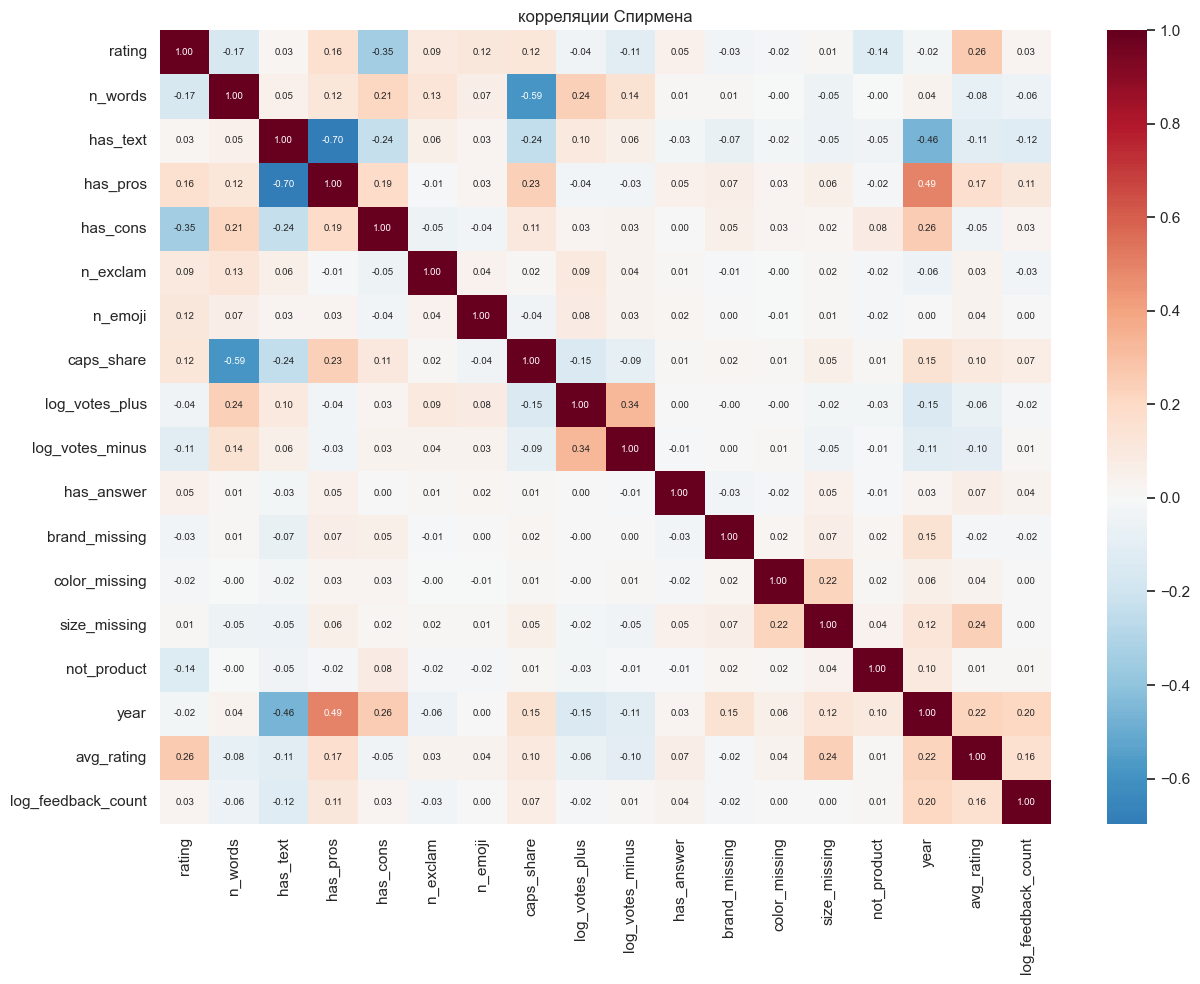

In [28]:
corr = reviews[['rating'] + FEATURES].corr(method='spearman')
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, ax=ax)
ax.set_title('корреляции Спирмена')
plt.tight_layout()
plt.show()

In [29]:
corr['rating'].drop('rating').sort_values(key=abs, ascending=False).round(3).to_frame('spearman с rating')

,spearman с rating
has_cons,-0.346
avg_rating,0.259
n_words,-0.166
has_pros,0.159
not_product,-0.136
caps_share,0.121
n_emoji,0.116
log_votes_minus,-0.109
n_exclam,0.092
has_answer,0.048


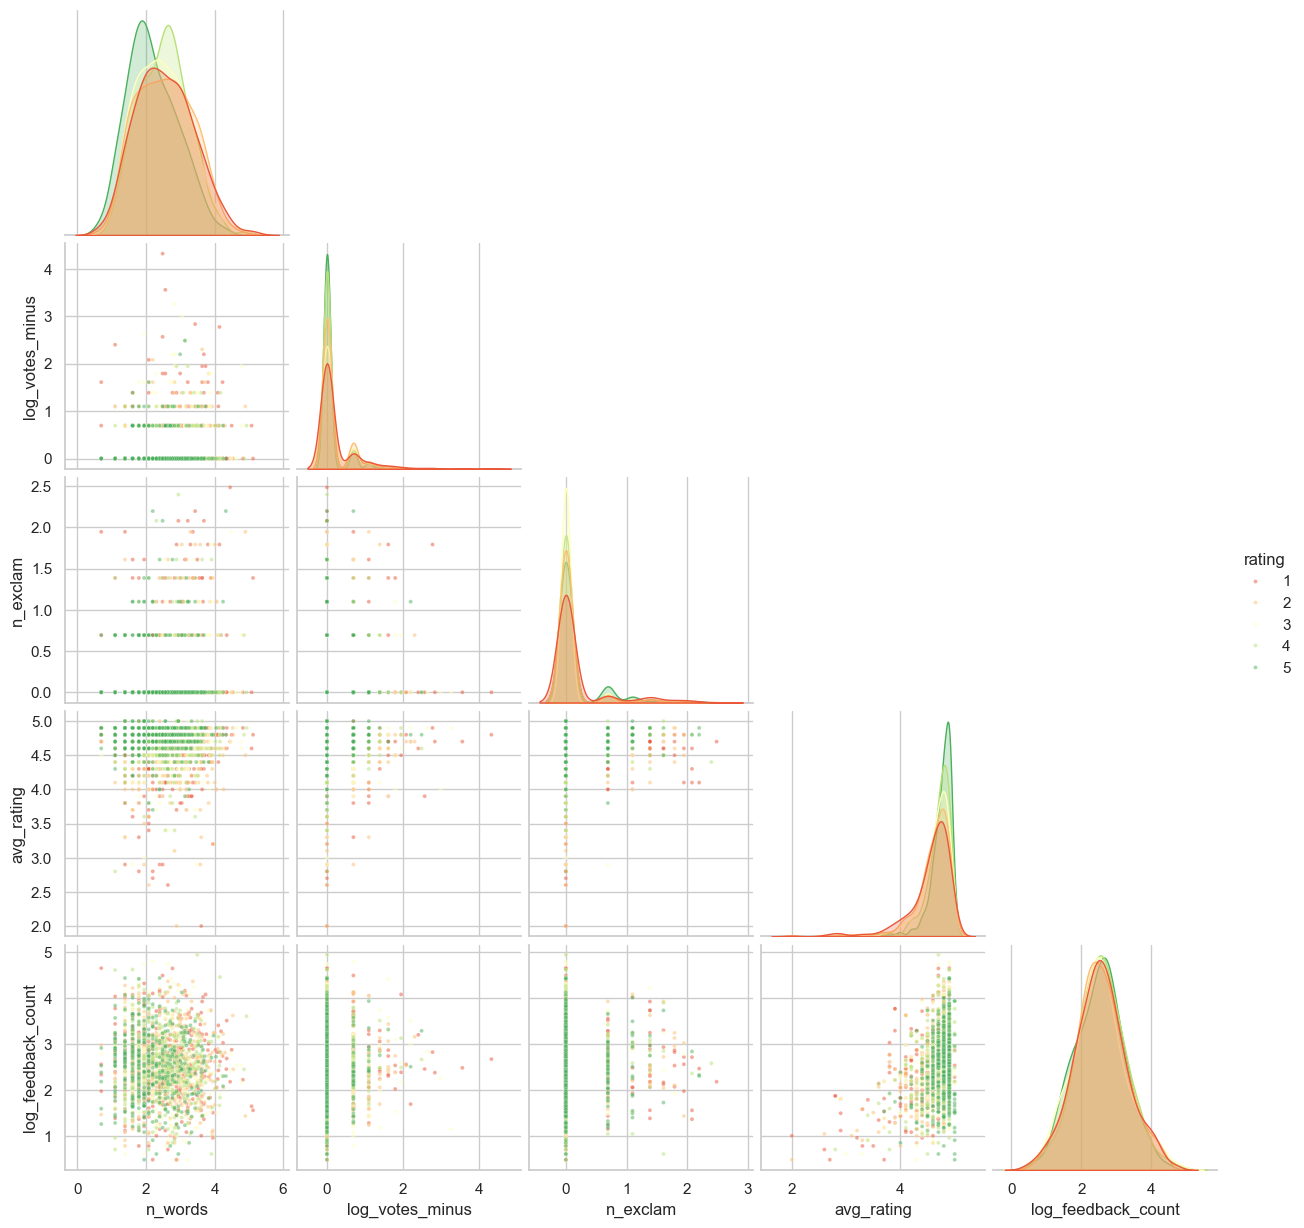

In [30]:
# pairplot на сбалансированной подвыборке, иначе всё закрашено пятёрками
pair_cols = ['n_words', 'log_votes_minus', 'n_exclam', 'avg_rating', 'log_feedback_count']
pair_sample = reviews.groupby('rating').sample(400, random_state=SEED)
pair_sample = pair_sample.assign(n_words=np.log1p(pair_sample.n_words), n_exclam=np.log1p(pair_sample.n_exclam))
sns.pairplot(pair_sample[pair_cols + ['rating']], hue='rating', palette=RATING_PALETTE,
             plot_kws={'s': 8, 'alpha': 0.5}, corner=True)
plt.show()

- Самая сильная связь с таргетом у `has_cons` (ρ = −0.35) и `avg_rating` (0.26, утечка, см. выше). Затем идут `n_words` (−0.17), `has_pros` (0.16), `not_product` (−0.14), `caps_share` и `n_emoji` (~0.12), `log_votes_minus` (−0.11).
- Все мета-признаки по отдельности слабые (|ρ| ≤ 0.35). **Основная информация в тексте**, мета-признаки можно использовать только как добавку.
- Сильные корреляции между признаками:
  - `has_text` ↔ `has_pros` (−0.70) и оба ↔ `year` (±0.5): смена формы отзыва, см. п. 6.
  - `n_words` ↔ `caps_share` (−0.59): в коротком тексте заглавная первая буква даёт большую долю. `caps_share` фактически дублирует длину, его лучше не брать.
  - `votes_plus` ↔ `votes_minus` (0.34): «заметность» отзыва.
- На pairplot классы 1–4 почти полностью перекрываются по мета-признакам. Отделяется только 5★ (короче тексты, выше `avg_rating`).

## 8. Текст: словарь и n-граммы

In [31]:
STOPWORDS = set('''и в во не что он на я с со как а то все она так его но да ты к у же вы за бы по только ее мне было вот
от меня еще нет о из ему теперь когда даже ну ли если уже или ни быть был него до вас там потом себя ничего ей может они
тут где есть надо ней для мы тебя их чем была сам без чего раз тоже себе под будет тогда кто этот того потому этого какой
здесь этом один мой тем чтобы нее были куда всех можно при хоть после над больше тот через эти нас про всего них какая
много эту моя свою этой перед лучше чуть том такой им более всегда конечно это достоинства недостатки очень всё'''.split())


def tokenize(s):
    """Lowercase cyrillic tokens without stopwords."""
    return [w for w in re.findall('[а-яё]+', s.lower()) if len(w) > 2 and w not in STOPWORDS]


tokens = reviews.full_text.apply(tokenize)
vocab = Counter(w for ts in tokens for w in ts)
print(f'уникальных слов: {len(vocab):,}, встречаются ≥5 раз: {sum(c >= 5 for c in vocab.values()):,}')
print(f'доля hapax (1 раз): {sum(c == 1 for c in vocab.values()) / len(vocab):.1%}  (опечатки, редкие формы)')

уникальных слов: 114,868, встречаются ≥5 раз: 27,294
доля hapax (1 раз): 52.5%  (опечатки, редкие формы)


In [32]:
# характерные слова: log-odds негатива (1–2★) против 5★
neg = Counter(w for ts in tokens[reviews.rating <= 2] for w in ts)
pos = Counter(w for ts in tokens[reviews.rating == 5] for w in ts)
mid = Counter(w for ts in tokens[reviews.rating.isin([3, 4])] for w in ts)
n_neg, n_pos, n_mid = sum(neg.values()), sum(pos.values()), sum(mid.values())
common = [w for w in vocab if vocab[w] >= 50]
log_odds = pd.Series({w: np.log((neg[w] + 1) / n_neg) - np.log((pos[w] + 1) / n_pos) for w in common})
mid_odds = pd.Series({w: np.log((mid[w] + 1) / n_mid) - np.log((neg[w] + pos[w] + 1) / (n_neg + n_pos)) for w in common})
pd.DataFrame({'1–2★': log_odds.nlargest(20).index, '5★': log_odds.nsmallest(20).index,
              '3–4★ (против крайних)': mid_odds.nlargest(20).index})

,1–2★,5★,3–4★ (против крайних)
0,отклонил,костюмчик,снизила
1,трата,находка,сняла
2,ужасное,стильная,троечку
3,потраченные,счастлив,звезду
4,отказал,лучшая,снимаю
5,отвратительный,отличные,звезды
6,отвратительное,шикарные,звезда
7,тратьте,любовь,звёзды
8,хрень,берём,странный
9,некачественный,комфортная,неудобная


In [33]:
# частые биграммы по оценкам
def top_bigrams(texts, k=10):
    """Most common bigrams in tokenized texts."""
    return [' '.join(b) for b, _ in Counter(b for ts in texts for b in zip(ts, ts[1:])).most_common(k)]


pd.DataFrame({f'{r}★': top_bigrams(tokens[reviews.rating == r]) for r in range(1, 6)})

,1★,2★,3★,4★,5★
0,деньги ветер,деньги ветер,качество хорошее,качество хорошее,спасибо продавцу
1,пункте выдачи,пункте выдачи,поэтому отказ,поэтому отказ,качество хорошее
2,слова совсем,своих денег,такую цену,сняла звезду,спасибо большое
3,ужасное качество,такую цену,цвет соответствует,одну звезду,качество отличное
4,качество ужасное,карточке товара,карточке товара,снимаю звезду,хорошее качество
5,товар пришел,цвет соответствует,внешний вид,минус звезда,рекомендую покупке
6,такие деньги,первой стирки,своих денег,такую цену,соответствует описанию
7,просто ужас,качество плохое,размер соответствует,цвет соответствует,хорошего качества
8,соответствует описанию,размер соответствует,соответствует фото,хорошего качества,отличное качество
9,такую цену,поэтому отказ,желать лучшего,внешний вид,размер соответствует


- Крайние классы хорошо разделяются лексикой: «брак», «возврат», «обман», «отвратительный» против «отлично», «восторге», «находка».
- Для 3–4★ характерны **явные «снижения»** («сняла звезду», «снизила», «на троечку», «среднее») и **умеренные претензии** («слабоват», «неудобная», «царапина», «неровно»). В биграммах 3★/4★ рядом стоят «качество хорошее» и «поэтому отказ»: тональность смешанная, мешок слов здесь будет ошибаться.
- Устойчивые выражения хорошо видны в биграммах: «деньги на ветер», «пункт выдачи» (жалобы на логистику), «спасибо продавцу».
- Много hapax-слов (опечатки, разговорная речь): лучше подойдут субсловные токенизаторы (BPE, fastText), чем словарь словоформ. Для TF-IDF нужна лемматизация.

## 9. Аугментации

In [34]:
rng = np.random.default_rng(SEED)


def random_deletion(s, p=0.15):
    """Drop each word with probability p."""
    words = s.split()
    kept = [w for w in words if rng.random() > p]
    return ' '.join(kept or words[:1])


def random_swap(s, n=1):
    """Swap n random pairs of words."""
    words = s.split()
    for _ in range(n if len(words) > 1 else 0):
        i, j = rng.choice(len(words), 2, replace=False)
        words[i], words[j] = words[j], words[i]
    return ' '.join(words)


def drop_field(row):
    """Keep only one of text/pros/cons."""
    parts = [p for p in [row.text, row.pros, row.cons] if p]
    return parts[rng.integers(len(parts))]


ex = reviews[(reviews.rating == 2) & (reviews.n_words.between(15, 30)) & (reviews.has_cons == 1)].sample(2, random_state=SEED)
for _, row in ex.iterrows():
    print('orig   :', row.full_text.replace('\n', ' / '))
    print('delete :', random_deletion(row.full_text).replace('\n', ' / '))
    print('swap   :', random_swap(row.full_text, 2).replace('\n', ' / '))
    print('field  :', drop_field(row).replace('\n', ' / '), '\n')

orig   : Достоинства: Красивый, конечно очень. Но после месяца хождения с ним, цвет потускнел и по краям слезла вся краска / Недостатки: Ожидала более качественный товар. Одно разочарование
delete : Достоинства: Красивый, Но после месяца хождения с ним, цвет и краям слезла вся краска Недостатки: Ожидала товар. Одно разочарование
swap   : Достоинства: Красивый, конечно очень. Но после месяца хождения с Недостатки: цвет потускнел и по краям слезла вся краска ним, Ожидала Одно качественный товар. более разочарование
field  : Красивый, конечно очень. Но после месяца хождения с ним, цвет потускнел и по краям слезла вся краска 

orig   : Не соответствует карточке товара / Достоинства: Даже не стала доставать из пакета, цвет абсолютно не соответствует, благо заказывала ещё коробки! / Недостатки: Не тот цвет который заявлен
delete : Не соответствует карточке Достоинства: Даже не стала доставать из пакета, цвет абсолютно не соответствует, благо заказывала ещё коробки! Не тот цвет который
swap  

| аугментация | подходит? | комментарий |
|---|---|---|
| Random deletion / swap (EDA-аугментации) | частично | дешёвые, сохраняют тональность; для коротких отзывов (медиана 8 слов) легко удаляют ключевое слово |
| Отбрасывание одного из полей text/pros/cons | да | естественная для данных аугментация: многие пользователи заполняют одно поле |
| Замена синонимами | частично | для русского нужен хороший тезаурус (RuWordNet); легко ломает тональность |
| Back-translation (ru→en→ru) | да | хорошо сохраняет смысл, особенно полезно для редких 2★ и 3★ |
| Перефразирование LLM | да | для балансировки миноритарных классов; нужен контроль, что оценка по смыслу не изменилась |
| Mixup эмбеддингов | для DL | работает для упорядоченных классов |

Аугментации нужны в первую очередь **для редких классов 2★ и 3★**. Альтернатива: просто допарсить данные, парсер это позволяет.

## 10. Бейзлайн: TF-IDF + логистическая регрессия

In [35]:
# split по товарам, чтобы отзывы одного товара не попали в train и test одновременно
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(reviews, groups=reviews.imt_id))
train, test = reviews.iloc[train_idx], reviews.iloc[test_idx]
print(f'train: {len(train):,}  test: {len(test):,}  общих товаров: {len(set(train.imt_id) & set(test.imt_id))}')

train: 241,595  test: 58,127  общих товаров: 0


In [36]:
# стратифицированные версии: поровну отзывов каждой оценки, андерсэмплинг внутри train и test
train_strat = train.groupby('rating').sample(n=train.rating.value_counts().min(), random_state=SEED)
test_strat = test.groupby('rating').sample(n=test.rating.value_counts().min(), random_state=SEED)
print(f'train_strat: {len(train_strat):,} ({len(train_strat) // 5:,} на класс)  '
      f'test_strat: {len(test_strat):,} ({len(test_strat) // 5:,} на класс)')

train_strat: 33,990 (6,798 на класс)  test_strat: 8,465 (1,693 на класс)


In [37]:
def evaluate(name, model, vec):
    """Accuracy, macro-F1 and MAE on the natural and the stratified test."""
    row = {'model': name}
    for suffix, df in [('', test), ('_strat', test_strat)]:
        y_pred = model.predict(vec.transform(df.full_text))
        row[f'accuracy{suffix}'] = accuracy_score(df.rating, y_pred)
        row[f'macro_f1{suffix}'] = f1_score(df.rating, y_pred, average='macro')
        row[f'mae{suffix}'] = mean_absolute_error(df.rating, y_pred)
    return row


def tfidf():
    """Word 1-2 gram tf-idf used by all baselines."""
    return TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=200_000, sublinear_tf=True)


vectorizer = tfidf()
x_train = vectorizer.fit_transform(train.full_text)
vectorizer_strat = tfidf()
x_train_strat = vectorizer_strat.fit_transform(train_strat.full_text)

dummy = DummyClassifier(strategy='most_frequent').fit(x_train, train.rating)
logreg = LogisticRegression(max_iter=1000, C=2.0).fit(x_train, train.rating)
logreg_bal = LogisticRegression(max_iter=1000, C=2.0, class_weight='balanced').fit(x_train, train.rating)
logreg_strat = LogisticRegression(max_iter=1000, C=2.0).fit(x_train_strat, train_strat.rating)

results = pd.DataFrame([
    evaluate('константа 5★', dummy, vectorizer),
    evaluate('tfidf + logreg', logreg, vectorizer),
    evaluate('tfidf + logreg (class_weight)', logreg_bal, vectorizer),
    evaluate('tfidf + logreg (stratified train)', logreg_strat, vectorizer_strat),
]).set_index('model').round(3)
results

,accuracy,macro_f1,mae,accuracy_strat,macro_f1_strat,mae_strat
model,,,,,,
константа 5★,0.756,0.172,0.580,0.200,0.067,2.000
tfidf + logreg,0.821,0.443,0.305,0.431,0.364,0.963
tfidf + logreg (class_weight),0.764,0.457,0.369,0.487,0.469,0.756
tfidf + logreg (stratified train),0.707,0.432,0.458,0.480,0.477,0.748


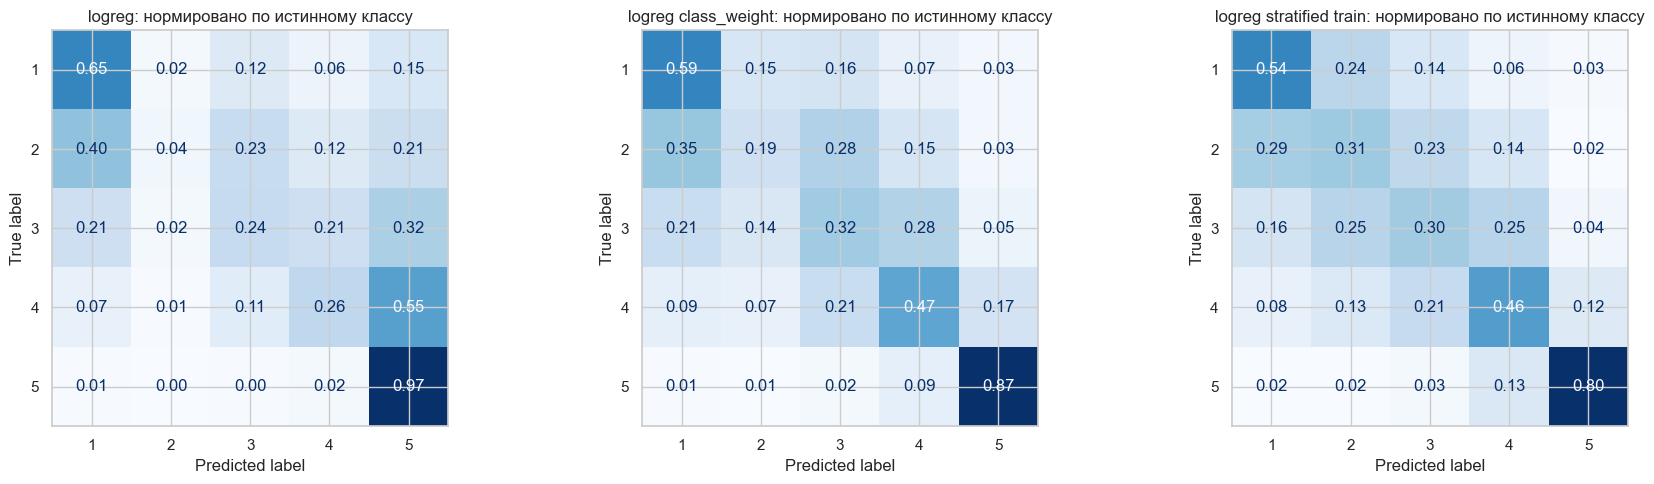

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models = [('logreg', logreg, vectorizer), ('logreg class_weight', logreg_bal, vectorizer),
          ('logreg stratified train', logreg_strat, vectorizer_strat)]
for ax, (name, model, vec) in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(test.rating, model.predict(vec.transform(test.full_text)), normalize='true',
                                            values_format='.2f', cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f'{name}: нормировано по истинному классу')
plt.tight_layout()
plt.show()

In [39]:
# интерпретация: n-граммы с наибольшими весами для каждого класса
feature_names = np.array(vectorizer.get_feature_names_out())
pd.DataFrame({f'{c}★': feature_names[np.argsort(coef)[-12:][::-1]]
              for c, coef in zip(logreg_bal.classes_, logreg_bal.coef_)})

,1★,2★,3★,4★,5★
0,не рекомендую,две звезды,три звезды,звезду,отличные
1,ужас,не рекомендую,звезды,но,отличная
2,не советую,подошло спасибо,да качество,немного,спасибо
3,ужасное,нравится спасибо,перезаказала надеюсь,минус,отличный
4,не соответствует,шины хорошие,много не,звезда,отлично
5,обман,запах рекомендую,размер точно,не плохой,супер
6,ужасный,золотая,отличаются,целом,хорошие
7,одна звезда,мутное,очень мелкие,хороший,недостатки нет
8,продавец,хлопок заказала,не устраивает,минус звезда,хорошая
9,деньги,но работает,удобный очень,не плохое,хороший


**Бейзлайн-качество** (с ним будем сравнивать дальнейшие модели) записано в таблице выше. Сравниваем три способа обучения:
- на всём train без весов;
- на всём train с `class_weight='balanced'`;
- на **стратифицированном train**: андерсэмплинг до 6.8k отзывов на класс, всего 34k, то есть 14% train.

Оцениваем на двух тестах: с реальным распределением (`test`) и стратифицированном (`test_strat`, по 1.7k на класс). Второй показывает качество на редких классах без перевеса пятёрок.
- Константа даёт accuracy 0.76 при macro-F1 ≈ 0.17. Это подтверждает, что accuracy здесь неинформативна.
- TF-IDF + LogReg уверенно определяет 5★ (recall 0.97) и 1★ (0.65). Основные ошибки в **2–4★**:
  - без весов модель почти не предсказывает 2★ (recall 0.04, 40% уходит в 1★), а 4★ в 55% случаев становится 5★;
  - с `class_weight='balanced'` recall 4★ растёт до 0.47, 3★ до 0.32. Ошибки в основном на соседние классы. Это поддерживает ординальную постановку и метрику MAE.
- `class_weight='balanced'` поднимает macro-F1 (0.443 → 0.457) ценой accuracy и MAE. Компромисс будем подбирать на следующем чекпойнте.
- **Стратифицированный train**, несмотря на 7× меньше данных, лучший на `test_strat` (macro-F1 0.477, MAE 0.75) и чаще всех правильно ставит 2★ (recall 0.31 против 0.04 и 0.19). Но на реальном распределении он хуже всех (accuracy 0.71, MAE 0.46): модель считает классы равновероятными и слишком часто «снимает» пятёрки (recall 5★ падает до 0.80).
- Вывод: андерсэмплинг и `class_weight` дают похожее качество на редких классах. `class_weight` использует все данные и лучше на реальном распределении, поэтому это основной вариант. Стратифицированный датасет полезен для быстрых экспериментов (в 7× меньше) и для честного сравнения качества по классам.
- Веса модели осмысленные: 1★ «не рекомендую», «обман», «не работает»; 3★ «три звезды», «не устраивает», «но маломерки»; 4★ «звезду», «но», «немного», «минус звезда», «в целом». У 2★ веса шумные («подошло спасибо», «шины хорошие»): класс маленький и самый «грязный».

## 11. Выводы

**Данные**
1. Собрано 300k отзывов (299.7k после очистки) на 9.2k товаров из 93 корневых категорий. Товары выбраны случайно, а не из поисковой выдачи.
2. Пропуски осмысленные: пустые поля формы, товары без вариантов (`color` / `size`, плюс скрытый пропуск `size='0'`) и no-name товары (`brand`, у них оценка ниже). Строки не удаляем: превращаем пропуски во флаги.
3. Формально ошибочных значений нет (оценки 1–5, корректные даты, уникальные id). Но WB сам помечает **шум в разметке** (`sentimentCollision`, текст противоречит оценке), эти 379 отзывов удалены. Отзывы о доставке (`notProduct`) помечены флагом.
4. Выбросы по длине и голосам это реальные развёрнутые отзывы и «заметные» отзывы, а не ошибки. Для счётчиков используем `log1p`, тексты обрезаем до ~128 токенов (покрывает >99%).

**Задача**

5. **Сильный дисбаланс** (76% пятёрок), поэтому метрики **macro-F1 + MAE**, а не accuracy. Распределение U-образное.
6. Главный источник информации это текст. Мета-признаки слабые (|ρ| ≤ 0.35), но полезные: `has_cons`, длина, `not_product`, категория, `brand_missing`. Поля «Достоинства» / «Недостатки» появились только в 2024 году, поэтому признаки «какие поля заполнены» зависят от года.
7. Отзывы одного товара скоррелированы, а `avg_rating` товара это утечка таргета. Отсюда **GroupKFold по `imt_id`** и запрет на признаки уровня товара, посчитанные по отзывам.
8. Крайние классы разделяются лексикой легко, средние (2–4) путаются между собой. Это задача на смешанную тональность («качество хорошее, но маломерит», «минус звезда за...»).
9. Бейзлайн TF-IDF + LogReg с `class_weight`: **macro-F1 0.457, MAE 0.37** против 0.172 / 0.58 у константы. Обучение на стратифицированном train даёт лучший macro-F1 на сбалансированном тесте (0.477), но проигрывает на реальном распределении. При обучении на balanced-данных нужно учитывать сдвиг априорных вероятностей.

**Как используем дальше (чекпойнт 3)**
- Бейзлайн TF-IDF + LogReg с group-split зафиксирован. Дальше:
  - классические модели (лемматизация, char n-граммы, бустинг на TF-IDF + мета-признаки);
  - эмбеддинги (fastText / ruBERT / мультиязычные модели для сравнения с Amazon);
  - ординальная регрессия.
- Для редких классов: `class_weight`, сбалансированный датасет, аугментации (выбрасывание полей, back-translation, LLM-перефразирование) или допарсинг.
- Для продакшена (сервис на чекпойнте 4): короткие тексты, поэтому лёгкие модели быстрые. Нужно учитывать дрейф: смена формы отзыва в 2024 году, смещение средней оценки, категории.

Практическая ценность проекта описана в `practical_value.pdf`.